In [1]:
import os

%load_ext autoreload
%autoreload 2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
from torch.distributions import Beta
from scipy.stats import levy_stable

import math
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_swiss_roll
from sklearn.utils import shuffle

from src_toys.fields import PFGMPPField, Field
from src_toys.interpolants import LinearInterpolant, QuadraticSigmaSchedule, LinearSigmaSchedule, SineCosineInterpolant

from IPython.display import clear_output
from torch.utils.data import DataLoader, TensorDataset

from tqdm.auto import tqdm

---

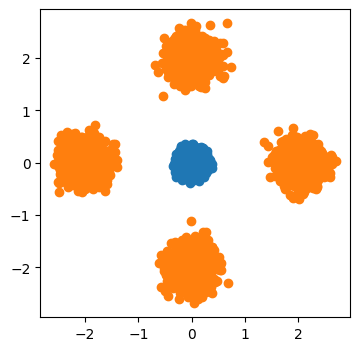

In [2]:
def get_dataset(ds_name, aux_dim=None, n_blobs=None, r_blobs=None, sigma_blobs=None):
    if ds_name == "swiss":
        def make_swiss_dataset(num_samples):
            X0, _ = make_swiss_roll(num_samples // 2, noise=0.3, random_state=0)
            X1, _ = make_swiss_roll(num_samples // 2, noise=0.3, random_state=0)
            X0 = X0[:, [0, 2]]
            X1 = X1[:, [0, 2]]
            X1 = -X1
            X, y = shuffle(
                np.concatenate([X0, X1], axis=0),
                np.concatenate([np.zeros(len(X0)), np.ones(len(X1))], axis=0),
                random_state=0)
            X = (X - X.mean(axis=0)) / X.std(axis=0)
        
            return X.astype(np.float32), y
        X, Y = make_swiss_dataset(5000)
        
    elif ds_name == "gaussian":
        sigma = .1
        ds_size = 10_000
        
        X = np.random.randn(ds_size, 2) * sigma
        Y = None

    elif ds_name == "gaussians":
        factor, sigma = 1., 0.2
        mu1, sigma1 = factor * np.array([-1, -1]), sigma
        mu2, sigma2 = factor * np.array([1, 1]), sigma
        ds_size = 5_000
        
        X1 = np.random.randn(ds_size//2, len(mu1)) * sigma1 + mu1
        Y1 = np.ones(len(X1)) * 0.
        X2 = np.random.randn(ds_size//2, len(mu2)) * sigma2 + mu2
        Y2 = np.ones(len(X2)) * 1.
        
        X = np.concatenate([X1, X2]).astype(np.float32)
        Y = np.concatenate([Y1, Y2])

    elif ds_name == "gaussians2":
        factor, sigma = 1., 0.2
        mu1, sigma1 = factor * np.array([1, -1]), sigma
        mu2, sigma2 = factor * np.array([-1, 1]), sigma
        ds_size = 5_000
        
        X1 = np.random.randn(ds_size//2, len(mu1)) * sigma1 + mu1
        Y1 = np.ones(len(X1)) * 0.
        X2 = np.random.randn(ds_size//2, len(mu2)) * sigma2 + mu2
        Y2 = np.ones(len(X2)) * 1.
        
        X = np.concatenate([X1, X2]).astype(np.float32)
        Y = np.concatenate([Y1, Y2])

    elif ds_name == "circle":
        R = 1.
        sigma = 0.05
        ds_size = 5000
        angle = np.random.rand(ds_size) * 2 * np.pi
        noise = np.random.randn(ds_size, 2) * sigma
        X = np.stack([np.sin(angle), np.cos(angle)], axis=1) + noise
        Y = None

    elif ds_name == "pfgmpp":
        eps = 1e-6
        ds_size = 10000
        sigma = 1. * torch.ones(ds_size) * aux_dim**0.5

        # Sample from inverse-beta distribution
        beta_gen = Beta(torch.FloatTensor([2. / 2.]), torch.FloatTensor([aux_dim / 2.]))
        beta_sample = beta_gen.sample((sigma.shape[0],)).reshape(-1)
        inverse_beta_sample = beta_sample / (1 - beta_sample).clamp(min=eps)

        # Sample from p(R)
        R = sigma * torch.sqrt(inverse_beta_sample.clamp(min=eps))

        # Sample angle
        gaussian = torch.randn(sigma.shape[0], 2, device=sigma.device, dtype=sigma.dtype)
        angle = gaussian / torch.norm(gaussian, p=2, dim=1, keepdim=True)

        X = np.asarray(R.view(-1, 1) * angle)
        Y = None
        
    elif ds_name == "stable":
        alpha = 1.7    # stability parameter
        beta = 0    # skewness parameter
        loc = 0        # location parameter
        scale = 0.05      # scale parameter
        
        # Generate samples
        X = np.stack([
            levy_stable.rvs(alpha, beta, loc=loc, scale=scale, size=10000),
            levy_stable.rvs(alpha, beta, loc=loc, scale=scale, size=10000),
        ], axis=-1)
        Y = None

    elif ds_name == "gaussians3":
        ds_size = 5_000

        centers = []
        for i in range(n_blobs):
            angle = np.pi / 2 - 2 * np.pi * i / n_blobs  # start from top, clockwise
            centers.append([r_blobs * np.cos(angle), r_blobs * np.sin(angle)])

        samples_per_blob = ds_size // n_blobs
        X_list, Y_list = [], []
        for i, mu in enumerate(centers):
            Xi = np.random.randn(samples_per_blob, 2) * sigma_blobs + np.array(mu)
            X_list.append(Xi)
            Y_list.append(np.ones(samples_per_blob) * i)

        X = np.concatenate(X_list).astype(np.float32)
        Y = np.concatenate(Y_list)

    return X.astype(np.float32), Y

### dataset 0 ###

X0, Y0 = get_dataset("gaussian")

plt.figure(figsize=(4, 4))
plt.scatter(x=X0[:, 0], y=X0[:, 1])
# plt.show()

### dataset 1 ###
X1, Y1 = get_dataset("gaussians3", n_blobs=4, r_blobs=2., sigma_blobs=0.2)

# plt.figure(figsize=(4, 4))
plt.scatter(x=X1[:, 0], y=X1[:, 1])
plt.show()

In [3]:
class SinTimeEmbed(nn.Module):
    def __init__(self, dim=64, max_freq=64.0):
        super().__init__()
        self.register_buffer("freqs", torch.exp(torch.linspace(0., math.log(max_freq), dim // 2)))
        self.dim = dim
        
    def forward(self, z):
        ang = z[:, None] * self.freqs[None, :] * 2 * math.pi
        emb = torch.cat([torch.sin(ang), torch.cos(ang)], dim=-1)
        if emb.shape[-1] < self.dim:
            emb = F.pad(emb, (0, self.dim - emb.shape[-1]))
        return emb

class VelocityMLP(nn.Module):
    def __init__(self, x_dim=2, t_dim=64, hidden=256, layers=3, out_dim=None):
        super().__init__()
        self.temb = SinTimeEmbed(t_dim)
        in_dim = x_dim + t_dim
        mods = []

        for i in range(layers):
            mods += [nn.Linear(in_dim if i==0 else hidden, hidden), nn.SiLU()]
        self.backbone = nn.Sequential(*mods)

        if out_dim is None:
            out_dim = x_dim
        self.out = nn.Linear(hidden, out_dim)

        nn.init.xavier_uniform_(self.out.weight, gain=0.1)
        nn.init.zeros_(self.out.bias)

    def forward(self, x, z):
        te = self.temb(z)
        h = torch.cat([x, te], dim=-1)

        return self.out(self.backbone(h))

In [4]:
def train_step(model, optimizer, field, x0, x1, loss_fn):
    """
    x1: (B, d) batch from the target distribution.
    x0: (B, d) batch from the target distribution.
    """
    device = next(model.parameters()).device
    x0 = x0.to(device)
    x1 = x1.to(device)

    optimizer.zero_grad(set_to_none=True)

    loss = loss_fn(model, field, x0, x1)
    
    loss.backward()
    optimizer.step()

    return float(loss.item())

In [5]:
class ExEzLoss:
    def __call__(
        self, net: nn.Module, field_to_sample_xt: Field, field_to_compute_E: Field, x0: Tensor, x1: Tensor, eps: float=1e-3
    ) -> Tensor:

        z = eps + torch.rand(x0.shape[0], device=x0.device) * (1 - 2 * eps)

        x = field_to_sample_xt.sample(z, x0, x1)
        E = field_to_compute_E.strength(x, z, x0, x1, unnormalized=False)

        v_target= E[:, :-1] / E[:, -1:]
        v_pred = net(x, z)

        return F.mse_loss(v_pred, v_target)

class ENormELoss:
    def __call__(
        self, net: nn.Module, field_to_sample_xt: Field, field_to_compute_E: Field, x0: Tensor, x1: Tensor, eps: float=1e-3
    ) -> Tensor:

        z = eps + torch.rand(x0.shape[0], device=x0.device) * (1 - 2 * eps)
        
        x = field_to_sample_xt.sample(z, x0, x1)
        E = field_to_compute_E.strength(x, z, x0, x1, unnormalized=True)

        E = E / E.norm(dim=-1, keepdim=True)

        E_pred = net(x, z)

        return F.mse_loss(E_pred, E)

---
## Ex / Ez Loss:

In [6]:
# batch_size = 512
# dl0 = DataLoader(TensorDataset(torch.tensor(X0)), batch_size=batch_size, shuffle=True, drop_last=True)
# dl1 = DataLoader(TensorDataset(torch.tensor(X1)), batch_size=batch_size, shuffle=True, drop_last=True)

lin_field = PFGMPPField(
    interpolant=LinearInterpolant(),
    sigma_schedule=QuadraticSigmaSchedule(0.05),
    data_dim=2,
)

sine_field = PFGMPPField(
    interpolant=SineCosineInterpolant(),
    sigma_schedule=QuadraticSigmaSchedule(0.05),
    data_dim=2,
)

### Experiments with correct p_vol: #####

experiment1 = {
    "field_to_sample_xt": lin_field,
    "field_to_compute_E": lin_field,
    "model": VelocityMLP(x_dim=2, out_dim=2),
    "loss_fn": ExEzLoss(),
    # "device": "cuda" if torch.cuda.is_available() else "cpu",
    "device": "cpu",
}

experiment2 = {
    "field_to_sample_xt": sine_field,
    "field_to_compute_E": sine_field,
    "model": VelocityMLP(x_dim=2, out_dim=2),
    "loss_fn": ExEzLoss(),
    # "device": "cuda" if torch.cuda.is_available() else "cpu",
    "device": "cpu",
}

experiment3 = {
    "field_to_sample_xt": lin_field,
    "field_to_compute_E": lin_field,
    "model": VelocityMLP(x_dim=2, out_dim=3),
    "loss_fn": ENormELoss(),
    # "device": "cuda" if torch.cuda.is_available() else "cpu",
    "device": "cpu",
}

experiment4 = {
    "field_to_sample_xt": sine_field,
    "field_to_compute_E": sine_field,
    "model": VelocityMLP(x_dim=2, out_dim=3),
    "loss_fn": ENormELoss(),
    # "device": "cuda" if torch.cuda.is_available() else "cpu",
    "device": "cpu",
}

### Experiments with x_t from one interpolant and E from another: #####

experiment5 = {
    "field_to_sample_xt": lin_field,
    "field_to_compute_E": sine_field,
    "model": VelocityMLP(x_dim=2, out_dim=2),
    "loss_fn": ExEzLoss(),
    # "device": "cuda" if torch.cuda.is_available() else "cpu",
    "device": "cpu",
}

experiment6 = {
    "field_to_sample_xt": sine_field,
    "field_to_compute_E": lin_field,
    "model": VelocityMLP(x_dim=2, out_dim=2),
    "loss_fn": ExEzLoss(),
    # "device": "cuda" if torch.cuda.is_available() else "cpu",
    "device": "cpu",
}

experiment7 = {
    "field_to_sample_xt": lin_field,
    "field_to_compute_E": sine_field,
    "model": VelocityMLP(x_dim=2, out_dim=3),
    "loss_fn": ENormELoss(),
    # "device": "cuda" if torch.cuda.is_available() else "cpu",
    "device": "cpu",
}

experiment8 = {
    "field_to_sample_xt": sine_field,
    "field_to_compute_E": lin_field,
    "model": VelocityMLP(x_dim=2, out_dim=3),
    "loss_fn": ENormELoss(),
    # "device": "cuda" if torch.cuda.is_available() else "cpu",
    "device": "cpu",
}

In [ ]:
def run_experiment(
    experiment: dict,
    X0, X1,
    exp_num: int = 0,
    n_epochs: int = 100,
    steps: int = 1000,
    log_every: int = 100,
    steps_ode_eval: int = 50,
    batch_size: int = 512,
    lr: float = 5e-4,
    checkpoint_dir: str = "checkpoints/multisample/",
    eval_every: int = 5,
):
    field_to_sample_xt = experiment["field_to_sample_xt"]
    field_to_compute_E = experiment["field_to_compute_E"]
    model = experiment["model"]
    loss_fn = experiment["loss_fn"]

    device = experiment.get("device", "cpu")

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    dl0 = DataLoader(TensorDataset(torch.tensor(X0)), batch_size=batch_size, shuffle=True, drop_last=True)
    dl1 = DataLoader(TensorDataset(torch.tensor(X1)), batch_size=batch_size, shuffle=True, drop_last=True)

    use_enorm = isinstance(loss_fn, ENormELoss)

    for epoch in range(n_epochs):
        it0 = iter(dl0)
        it1 = iter(dl1)

        pbar = tqdm(range(1, steps + 1), desc=f"Epoch {epoch}")
        for step in pbar:
            try:
                (x0,) = next(it0)
            except StopIteration:
                it0 = iter(dl0)
                (x0,) = next(it0)
            try:
                (x1,) = next(it1)
            except StopIteration:
                it1 = iter(dl1)
                (x1,) = next(it1)

            x0 = x0.to(device)
            x1 = x1.to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model, field_to_sample_xt, field_to_compute_E, x0, x1)
            loss.backward()
            optimizer.step()

            if step % log_every == 0:
                pbar.set_postfix(loss=f"{float(loss.detach()):.4f}")

        if (epoch + 1) % eval_every == 0:
            with torch.no_grad():
                B = 5000
                x = torch.tensor(X0[:B], device=device)
                z = torch.zeros(B, device=device)
                dz = 1.0 / steps_ode_eval
                for _ in range(steps_ode_eval):
                    if use_enorm:
                        E1 = model(x, z)
                        v1 = E1[:, :-1] / E1[:, -1:]
                        x_euler = x + dz * v1
                        z_next = (z + dz).clamp_(0.0, 1.0)
                        E2 = model(x_euler, z_next)
                        v2 = E2[:, :-1] / E2[:, -1:]
                    else:
                        v1 = model(x, z)
                        x_euler = x + dz * v1
                        z_next = (z + dz).clamp_(0.0, 1.0)
                        v2 = model(x_euler, z_next)
                    x = x + 0.5 * dz * (v1 + v2)
                    z = z_next

                samples = x.cpu()

            try:
                clear_output()
                plt.figure(figsize=(4, 4))
                plt.scatter(X1[:B, 0], X1[:B, 1], s=2, alpha=0.6)
                plt.scatter(samples[:, 0], samples[:, 1], s=2, alpha=0.6)
                plt.axis("equal")
                plt.tight_layout()
                plt.show()
            except Exception:
                pass

    os.makedirs(checkpoint_dir, exist_ok=True)
    torch.save(model.state_dict(), os.path.join(checkpoint_dir, f"exp{exp_num}.pt"))

    with torch.no_grad():
        B = 5000
        x = torch.tensor(X0[:B], device=device)
        z = torch.zeros(B, device=device)
        dz = 1.0 / steps_ode_eval
        for _ in range(steps_ode_eval):
            if use_enorm:
                E1 = model(x, z)
                v1 = E1[:, :-1] / E1[:, -1:]
                x_euler = x + dz * v1
                z_next = (z + dz).clamp_(0.0, 1.0)
                E2 = model(x_euler, z_next)
                v2 = E2[:, :-1] / E2[:, -1:]
            else:
                v1 = model(x, z)
                x_euler = x + dz * v1
                z_next = (z + dz).clamp_(0.0, 1.0)
                v2 = model(x_euler, z_next)
            x = x + 0.5 * dz * (v1 + v2)
            z = z_next
        samples = x.cpu()

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.scatter(X1[:B, 0], X1[:B, 1], s=2, alpha=0.6)
    ax.scatter(samples[:, 0], samples[:, 1], s=2, alpha=0.6)
    ax.axis("equal")
    fig.tight_layout()
    fig.savefig(os.path.join(checkpoint_dir, f"exp{exp_num}.png"))
    plt.close(fig)

    return model

**Uncomment below to train:**

In [ ]:
for exp_num, exp in enumerate(
    [
        experiment1, experiment2, experiment3, experiment4,
        experiment5, experiment6, experiment7, experiment8
    ], start=1
):
    run_experiment(exp, X0, X1, exp_num=exp_num, steps_ode_eval=500, n_epochs=50, lr=5e-4)


---
## Part 2: Show, that $E_x / E_z $ is the same for both losses if use the same interpolant, but different for different interpolants

In [9]:
batch_size = 512
dl0 = DataLoader(TensorDataset(torch.tensor(X0)), batch_size=batch_size, shuffle=True, drop_last=True)
dl1 = DataLoader(TensorDataset(torch.tensor(X1)), batch_size=batch_size, shuffle=True, drop_last=True)

In [10]:
checkpoint_dir = "checkpoints/multisample"

### exps: 1, 2, 5, 6 ###
ckpt_path_ex_ez1 = f"{checkpoint_dir}/exp1.pt"
ckpt_path_ex_ez2 = f"{checkpoint_dir}/exp2.pt"

model_ex_ez1 = VelocityMLP(x_dim=2, out_dim=2)
model_ex_ez1.load_state_dict(torch.load(ckpt_path_ex_ez1, map_location="cpu"))

model_ex_ez2 = VelocityMLP(x_dim=2, out_dim=2)
model_ex_ez2.load_state_dict(torch.load(ckpt_path_ex_ez2, map_location="cpu"))

### exps: 3, 4, 7, 8 ###
ckpt_path_enorm1 = f"{checkpoint_dir}/exp3.pt"
ckpt_path_enorm2 = f"{checkpoint_dir}/exp4.pt"

model_enorm1 = VelocityMLP(x_dim=2, out_dim=3)
model_enorm1.load_state_dict(torch.load(ckpt_path_enorm1, map_location="cpu"))

model_enorm2 = VelocityMLP(x_dim=2, out_dim=3)
model_enorm2.load_state_dict(torch.load(ckpt_path_enorm2, map_location="cpu"))

<All keys matched successfully>

In [ ]:
from statistics import mean, stdev

device = "cuda" if torch.cuda.is_available() else "cpu"
k = 10
n_steps = 10
metric_history = {
    "v_pred1  vs  v_pred2": [],
    "v_from_E1  vs  v_from_E2": [],
    "v_pred1  vs  v_from_E1": [],
    "v_pred2  vs  v_from_E2": [],
}

relative_history = {label: [] for label in metric_history}

model_ex_ez1.to(device)
model_ex_ez2.to(device)
model_enorm1.to(device)
model_enorm2.to(device)

with torch.no_grad():
    for _ in range(k):
        it0 = iter(dl0)
        it1 = iter(dl1)

        mse_v1_v2 = 0.0
        mse_vE1_vE2 = 0.0
        mse_v1_vE1 = 0.0
        mse_v2_vE2 = 0.0
        relative_sums = {label: 0.0 for label in metric_history}

        for _ in range(n_steps):
            try:
                (x0,) = next(it0)
            except StopIteration:
                it0 = iter(dl0)
                (x0,) = next(it0)
            try:
                (x1,) = next(it1)
            except StopIteration:
                it1 = iter(dl1)
                (x1,) = next(it1)

            x0 = x0.to(device)
            x1 = x1.to(device)

            eps = 1e-3
            z = eps + torch.rand(x0.shape[0], device=device) * (1 - 2 * eps)
            x = x0 + z.view(-1, 1) * (x1 - x0)

            v_pred1 = model_ex_ez1(x, z)
            v_pred2 = model_ex_ez2(x, z)

            E_pred1 = model_enorm1(x, z)
            E_pred2 = model_enorm2(x, z)

            v_from_E1 = E_pred1[:, :-1] / E_pred1[:, -1:]
            v_from_E2 = E_pred2[:, :-1] / E_pred2[:, -1:]

            comparisons = [
                (v_pred1, v_pred2),
                (v_from_E1, v_from_E2),
                (v_pred1, v_from_E1),
                (v_pred2, v_from_E2),
            ]
            for label, (reference, estimate) in zip(metric_history, comparisons):
                error_sq = (estimate - reference).square().sum(dim=-1)
                reference_sq = reference.square().sum(dim=-1).clamp_min(1e-12)
                relative_sums[label] += (error_sq / reference_sq).mean().item()

            mse_v1_v2 += F.mse_loss(v_pred1, v_pred2).item()
            mse_vE1_vE2 += F.mse_loss(v_from_E1, v_from_E2).item()
            mse_v1_vE1 += F.mse_loss(v_pred1, v_from_E1).item()
            mse_v2_vE2 += F.mse_loss(v_pred2, v_from_E2).item()

        metric_history["v_pred1  vs  v_pred2"].append(mse_v1_v2 / n_steps)
        metric_history["v_from_E1  vs  v_from_E2"].append(mse_vE1_vE2 / n_steps)
        metric_history["v_pred1  vs  v_from_E1"].append(mse_v1_vE1 / n_steps)
        metric_history["v_pred2  vs  v_from_E2"].append(mse_v2_vE2 / n_steps)
        for label in relative_history:
            relative_history[label].append(relative_sums[label] / n_steps)

rows = [
    (label, mean(values), stdev(values) if len(values) > 1 else 0.0)
    for label, values in metric_history.items()
]

col_w = max(len(r[0]) for r in rows) + 2
print(f"{'Comparison':<{col_w}}  {'Mean':>12}  {'Std':>12}")
print("-" * (col_w + 28))
for label, val_mean, val_std in rows:
    print(f"{label:<{col_w}}  {val_mean:>12.6f}  {val_std:>12.6f}")
print("\nRelMSE (Eq. 41; first drift is reference):")
for label, values in relative_history.items():
    spread = stdev(values) if len(values) > 1 else 0.0
    print(f"{label}: {mean(values):.6g} +/- {spread:.6g}")
